In [1]:

# STEP 1: Install required libraries

!pip install yfinance nltk scikit-learn pandas numpy matplotlib seaborn wordcloud -q

print("All required libraries installed successfully!")


All required libraries installed successfully!


In [2]:

# STEP 2: Import required libraries

import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import re

from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

nltk.download('vader_lexicon')

print("Libraries imported successfully!")


[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


Libraries imported successfully!


In [3]:

# STEP 3: Create sample social media dataset

posts = [
    "The company reported excellent quarterly profits",
    "Stock prices are increasing steadily",
    "Investors are happy with the company performance",
    "The company announced a new business partnership",
    "Strong revenue growth this quarter",
    "The company is performing very well",
    "Shares are showing positive growth",
    "Excellent financial results announced",
    "The company is expanding its business",
    "Good news for investors",

    "The company reported a major financial loss",
    "Stock prices are falling rapidly",
    "Investors are disappointed with performance",
    "The company faces serious business challenges",
    "Revenue has declined significantly",
    "Shares are performing poorly",
    "Weak quarterly financial results",
    "Market uncertainty is increasing",
    "The company reported declining profits",
    "Bad news for shareholders",

    "The company announced its quarterly results",
    "The stock market opened today",
    "Investors are monitoring company shares",
    "The company scheduled a board meeting",
    "Trading volume remained unchanged",
    "The company released a financial statement",
    "Shares are trading at the current market price",
    "The company announced a meeting",
    "Financial analysts reviewed the report",
    "The market closed today"
]

companies = ["TCS", "Infosys", "Wipro"]

data = []

for i in range(100):
    post = posts[i % len(posts)]

    data.append({
        "Date": pd.Timestamp("2025-01-01") +
                pd.Timedelta(days=i),
        "Company": companies[i % 3],
        "Post": post
    })

social_df = pd.DataFrame(data)

# Save dataset
social_df.to_csv("social_media_posts.csv", index=False)

print("Social media dataset created successfully!")
print("Dataset shape:", social_df.shape)

social_df.head(10)


Social media dataset created successfully!
Dataset shape: (100, 3)


,Date,Company,Post
0,2025-01-01,TCS,The company reported excellent quarterly profits
1,2025-01-02,Infosys,Stock prices are increasing steadily
2,2025-01-03,Wipro,Investors are happy with the company performance
3,2025-01-04,TCS,The company announced a new business partnership
4,2025-01-05,Infosys,Strong revenue growth this quarter
5,2025-01-06,Wipro,The company is performing very well
6,2025-01-07,TCS,Shares are showing positive growth
7,2025-01-08,Infosys,Excellent financial results announced
8,2025-01-09,Wipro,The company is expanding its business
9,2025-01-10,TCS,Good news for investors


In [4]:

# STEP 4: Download historical stock data

ticker = "TCS.NS"

stock_df = yf.download(
    ticker,
    start="2024-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)

# Clean column names
if isinstance(stock_df.columns, pd.MultiIndex):
    stock_df.columns = stock_df.columns.get_level_values(0)

stock_df = stock_df.reset_index()

# Save dataset
stock_df.to_csv("stock_data.csv", index=False)

print("Historical stock dataset downloaded!")
print("Dataset shape:", stock_df.shape)

stock_df.head()


Historical stock dataset downloaded!
Dataset shape: (495, 6)


Price,Date,Close,High,Low,Open,Volume
0,2024-01-01,3464.368652,3483.367095,3429.734877,3445.188228,825907
1,2024-01-02,3439.006348,3464.368153,3424.507515,3464.368153,1344068
2,2024-01-03,3355.876465,3428.689096,3351.604113,3424.280258,1803075
3,2024-01-04,3333.197021,3380.647856,3318.834451,3364.967249,3598144
4,2024-01-05,3397.827393,3406.781333,3340.513832,3340.650096,1963127


In [5]:

# STEP 5: Sentiment Analysis using VADER

from nltk.sentiment.vader import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

# Function to classify sentiment
def analyze_sentiment(text):

    score = sia.polarity_scores(text)

    compound = score['compound']

    if compound >= 0.05:
        sentiment = "Positive"

    elif compound <= -0.05:
        sentiment = "Negative"

    else:
        sentiment = "Neutral"

    return sentiment, compound

# Apply sentiment analysis
social_df[['Sentiment', 'Sentiment_Score']] = social_df['Post'].apply(
    lambda x: pd.Series(analyze_sentiment(x))
)

# Display results
print("Sentiment analysis completed!")

social_df[['Company', 'Post', 'Sentiment', 'Sentiment_Score']].head(15)


Sentiment analysis completed!


,Company,Post,Sentiment,Sentiment_Score
0,TCS,The company reported excellent quarterly profits,Positive,0.7650
1,Infosys,Stock prices are increasing steadily,Neutral,0.0000
2,Wipro,Investors are happy with the company performance,Positive,0.5719
3,TCS,The company announced a new business partnership,Neutral,0.0000
4,Infosys,Strong revenue growth this quarter,Positive,0.7096
5,Wipro,The company is performing very well,Positive,0.3384
6,TCS,Shares are showing positive growth,Positive,0.8126
7,Infosys,Excellent financial results announced,Positive,0.5719
8,Wipro,The company is expanding its business,Neutral,0.0000
9,TCS,Good news for investors,Positive,0.4404


In [6]:

# Save sentiment analysis results

social_df.to_csv("sentiment_analysis_results.csv", index=False)

print("Sentiment results saved successfully!")


Sentiment results saved successfully!


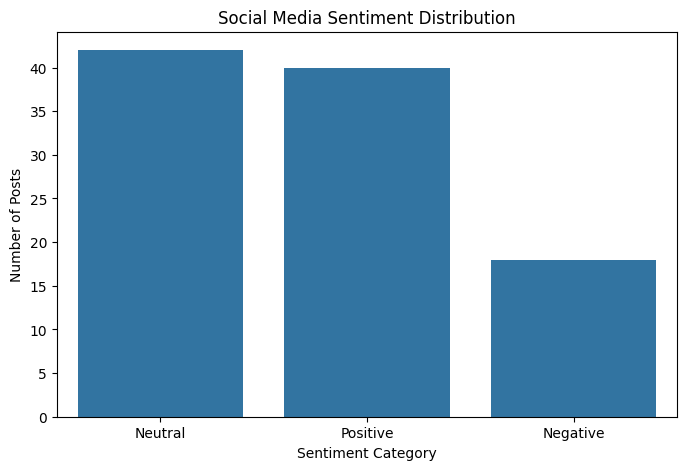

In [7]:

# STEP 6: Sentiment Distribution Graph

sentiment_counts = social_df['Sentiment'].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

plt.title("Social Media Sentiment Distribution")
plt.xlabel("Sentiment Category")
plt.ylabel("Number of Posts")

plt.show()


In [8]:

# STEP 7: Trending Topic Identification

from sklearn.feature_extraction.text import CountVectorizer

# Combine all posts
all_posts = social_df['Post'].astype(str)

# Convert text into word frequency features
vectorizer = CountVectorizer(
    stop_words='english',
    max_features=15
)

word_matrix = vectorizer.fit_transform(all_posts)

# Calculate word frequencies
word_counts = np.asarray(
    word_matrix.sum(axis=0)
).flatten()

words = vectorizer.get_feature_names_out()

trending_df = pd.DataFrame({
    'Topic': words,
    'Frequency': word_counts
})

trending_df = trending_df.sort_values(
    by='Frequency',
    ascending=False
)

print("Top Trending Topics:")

display(trending_df.head(10))


Top Trending Topics:


,Topic,Frequency
2,company,44
4,financial,16
0,announced,14
6,investors,14
13,shares,13
7,market,12
1,business,11
12,results,10
14,stock,10
11,reported,10


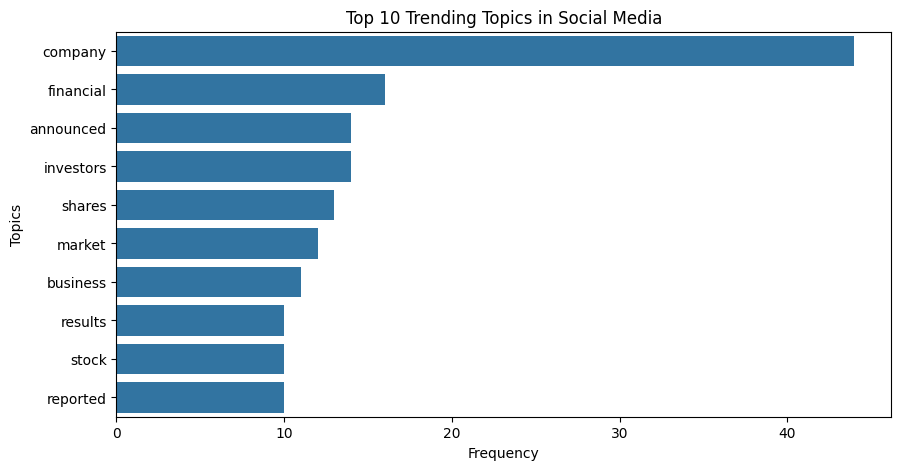

In [9]:

# STEP 8: Trending Topics Visualization

top_topics = trending_df.head(10)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=top_topics,
    x='Frequency',
    y='Topic'
)

plt.title("Top 10 Trending Topics in Social Media")
plt.xlabel("Frequency")
plt.ylabel("Topics")

plt.show()


Company-wise Sentiment Report


Sentiment,Negative,Neutral,Positive
Company,,,
Infosys,9,13,11
TCS,3,13,18
Wipro,6,16,11


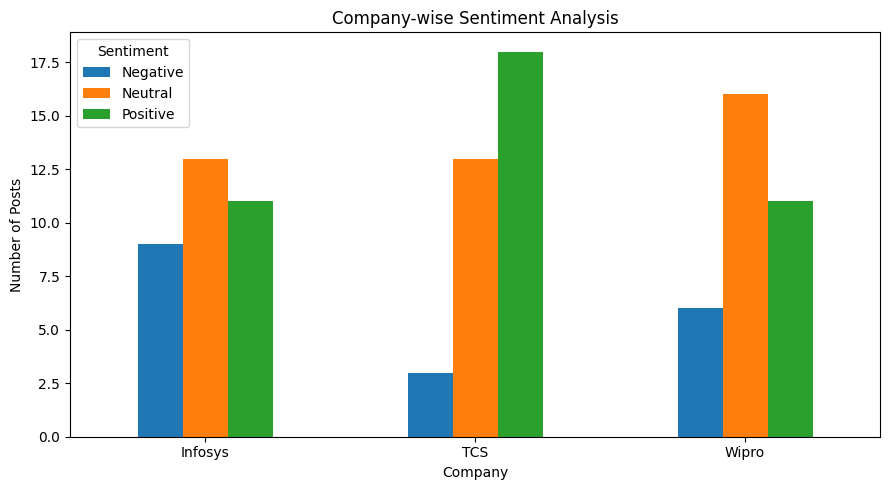

In [10]:

# STEP 9: Company-wise Sentiment Report

company_sentiment = pd.crosstab(
    social_df['Company'],
    social_df['Sentiment']
)

print("Company-wise Sentiment Report")

display(company_sentiment)

# Visualize company sentiment
company_sentiment.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title("Company-wise Sentiment Analysis")
plt.xlabel("Company")
plt.ylabel("Number of Posts")
plt.xticks(rotation=0)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()


In [11]:

# STEP 10: Combine financial data with sentiment data

# Prepare stock data
stock_df['Date'] = pd.to_datetime(stock_df['Date']).dt.normalize()

stock_df = stock_df.sort_values('Date').copy()

# Prepare sentiment data
social_df['Date'] = pd.to_datetime(social_df['Date']).dt.normalize()

# Aggregate sentiment by date
daily_sentiment = social_df.groupby('Date').agg(
    daily_sentiment=('Sentiment_Score', 'mean'),
    positive_ratio=('Sentiment', lambda x: (x == 'Positive').mean()),
    negative_ratio=('Sentiment', lambda x: (x == 'Negative').mean()),
    neutral_ratio=('Sentiment', lambda x: (x == 'Neutral').mean()),
    post_count=('Post', 'count')
).reset_index()

# Match each trading day with the latest available sentiment
combined_df = pd.merge_asof(
    stock_df.sort_values('Date'),
    daily_sentiment.sort_values('Date'),
    on='Date',
    direction='backward'
)

# Remove rows without sentiment information
combined_df = combined_df.dropna(
    subset=['daily_sentiment']
).copy()

print("Stock and sentiment datasets combined!")
display(combined_df.head())
print("Combined dataset shape:", combined_df.shape)


Stock and sentiment datasets combined!


,Date,Close,High,Low,Open,Volume,daily_sentiment,positive_ratio,negative_ratio,neutral_ratio,post_count
246,2025-01-01,3809.783447,3829.747237,3784.770358,3793.061614,763161,0.7650,1.0,0.0,0.0,1.0
247,2025-01-02,3868.424316,3875.140733,3795.423998,3816.777389,1720835,0.0000,0.0,0.0,1.0,1.0
248,2025-01-03,3798.156738,3872.315515,3791.116216,3872.315515,1791953,0.5719,1.0,0.0,0.0,1.0
249,2025-01-06,3793.617432,3844.245227,3767.122235,3803.344656,2085593,0.3384,1.0,0.0,0.0,1.0
250,2025-01-07,3731.826416,3835.629839,3716.309178,3812.099311,2669054,0.8126,1.0,0.0,0.0,1.0


Combined dataset shape: (249, 11)


In [12]:

# STEP 11: Financial Feature Engineering

combined_df = combined_df.sort_values('Date').copy()

# Daily stock returns
combined_df['Daily_Return'] = combined_df['Close'].pct_change(fill_method=None)

# Previous day's return
combined_df['Previous_Return'] = combined_df['Daily_Return'].shift(1)

# Moving averages
combined_df['MA_5'] = combined_df['Close'].rolling(window=5).mean()
combined_df['MA_10'] = combined_df['Close'].rolling(window=10).mean()

# Price volatility
combined_df['Volatility'] = combined_df['Daily_Return'].rolling(window=5).std()

# Trading volume change
combined_df['Volume_Change'] = combined_df['Volume'].pct_change(fill_method=None)

# Next day's closing price
combined_df['Next_Close'] = combined_df['Close'].shift(-1)

# Prediction target
combined_df['Target'] = np.where(
    combined_df['Next_Close'].notna(),
    (combined_df['Next_Close'] > combined_df['Close']).astype(int),
    np.nan
)

# Remove missing values
combined_df.replace([np.inf, -np.inf], np.nan, inplace=True)
combined_df.dropna(inplace=True)

print("Feature engineering completed!")
display(combined_df.head())


Feature engineering completed!


,Date,Close,High,Low,Open,Volume,daily_sentiment,positive_ratio,negative_ratio,neutral_ratio,post_count,Daily_Return,Previous_Return,MA_5,MA_10,Volatility,Volume_Change,Next_Close,Target
255,2025-01-14,3921.507324,3996.407045,3908.537691,3985.382948,3441709,0.0000,0.0,0.0,1.0,1.0,-0.013528,0.005966,3879.226318,3839.793994,0.029675,-0.140383,3936.839111,1.0
256,2025-01-15,3936.839111,3943.185057,3897.791347,3907.564710,1653474,0.0000,0.0,0.0,1.0,1.0,0.003910,-0.013528,3905.387988,3852.499561,0.029243,-0.519578,3896.726074,0.0
257,2025-01-16,3896.726074,3977.971742,3883.339831,3946.474062,2637705,0.2960,1.0,0.0,0.0,1.0,-0.010189,0.003910,3936.413232,3855.329736,0.027986,0.595250,3891.065186,0.0
258,2025-01-17,3891.065186,3925.312649,3868.186555,3924.652051,1761466,-0.4404,0.0,1.0,0.0,1.0,-0.001453,-0.010189,3924.284619,3864.620581,0.008559,-0.332197,3847.195068,0.0
259,2025-01-20,3847.195068,3911.349348,3838.043662,3911.349348,1287799,-0.5423,0.0,1.0,0.0,1.0,-0.011275,-0.001453,3898.666553,3869.978345,0.007410,-0.268905,3807.617188,0.0


In [13]:

# STEP 12: Baseline and Sentiment-Enhanced Models

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Features for baseline model (stock prices only)
baseline_features = [
    'Open', 'High', 'Low', 'Close', 'Volume',
    'Daily_Return', 'Previous_Return',
    'MA_5', 'MA_10', 'Volatility', 'Volume_Change'
]

# Features for enhanced model (stock + sentiment)
enhanced_features = baseline_features + [
    'daily_sentiment',
    'positive_ratio',
    'negative_ratio',
    'neutral_ratio',
    'post_count'
]

X = combined_df[baseline_features]
X_enhanced = combined_df[enhanced_features]
y = combined_df['Target'].astype(int)

# Chronological 80:20 split
split_index = int(len(combined_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

X_enhanced_train = X_enhanced.iloc[:split_index]
X_enhanced_test = X_enhanced.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Baseline model
baseline_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

# Sentiment-enhanced model
enhanced_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

enhanced_model.fit(X_enhanced_train, y_train)

enhanced_predictions = enhanced_model.predict(X_enhanced_test)

print("Both prediction models trained successfully!")


Both prediction models trained successfully!


In [14]:

# STEP 13: Model Evaluation

def evaluate_model(actual, predicted, model_name):

    return {
        'Model': model_name,
        'Accuracy': accuracy_score(actual, predicted),
        'Precision': precision_score(
            actual, predicted, zero_division=0
        ),
        'Recall': recall_score(
            actual, predicted, zero_division=0
        ),
        'F1 Score': f1_score(
            actual, predicted, zero_division=0
        )
    }

results = []

results.append(
    evaluate_model(
        y_test,
        baseline_predictions,
        'Baseline (Stock Only)'
    )
)

results.append(
    evaluate_model(
        y_test,
        enhanced_predictions,
        'Enhanced (Stock + Sentiment)'
    )
)

results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")

display(results_df.round(4))


MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Baseline (Stock Only),0.5000,0.50,0.1667,0.2500
1,Enhanced (Stock + Sentiment),0.5417,0.75,0.1250,0.2143


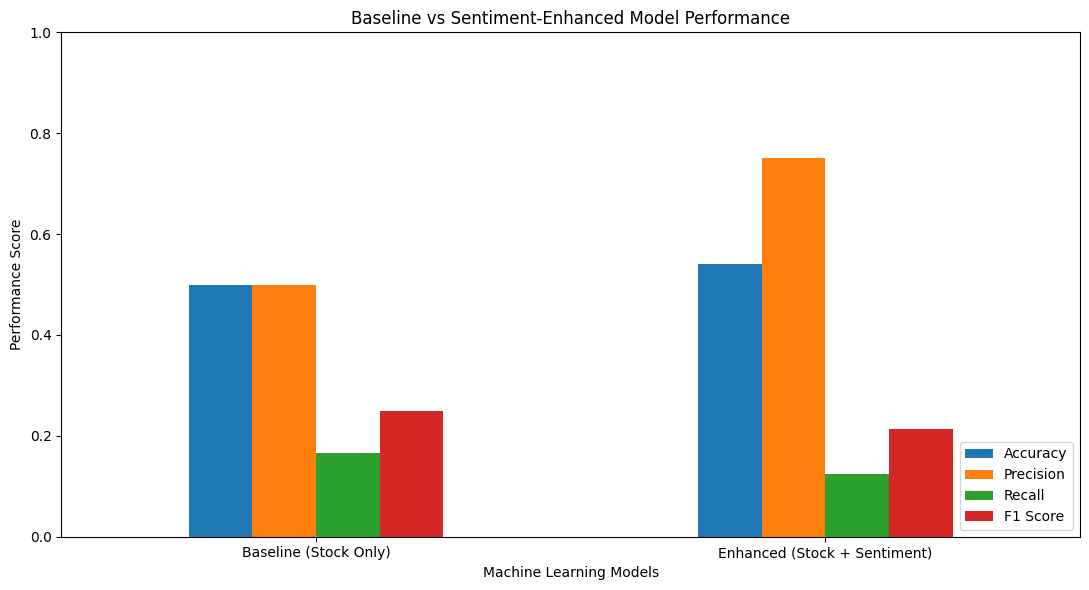

In [15]:

# STEP 14: Compare Model Performance

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

comparison = results_df.set_index('Model')[metrics]

comparison.plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title("Baseline vs Sentiment-Enhanced Model Performance")
plt.ylabel("Performance Score")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


In [16]:

# STEP 15: Save project outputs

combined_df.to_csv("combined_financial_sentiment_data.csv", index=False)

results_df.to_csv("model_comparison_results.csv", index=False)

print("Financial dataset saved!")
print("Model comparison saved!")


Financial dataset saved!
Model comparison saved!


In [17]:

# STEP 16: Predict Stock Market Direction

latest_data = combined_df[enhanced_features].tail(1)

prediction = enhanced_model.predict(latest_data)[0]

if prediction == 1:
    print("Predicted Financial Trend: UPWARD TREND")
else:
    print("Predicted Financial Trend: DOWNWARD TREND")

print("Prediction based on the latest available sample data.")


Predicted Financial Trend: DOWNWARD TREND
Prediction based on the latest available sample data.


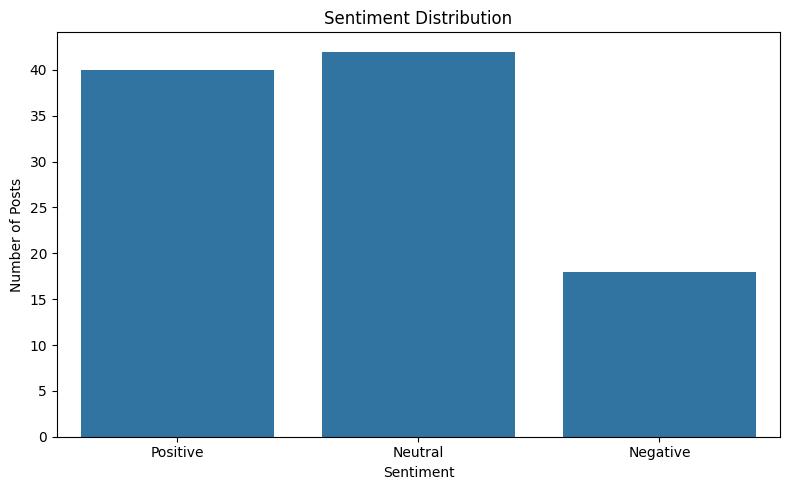

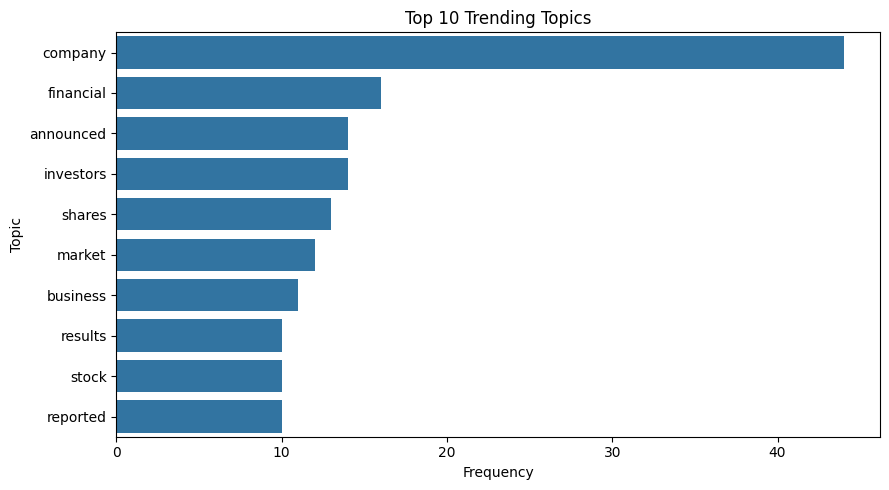

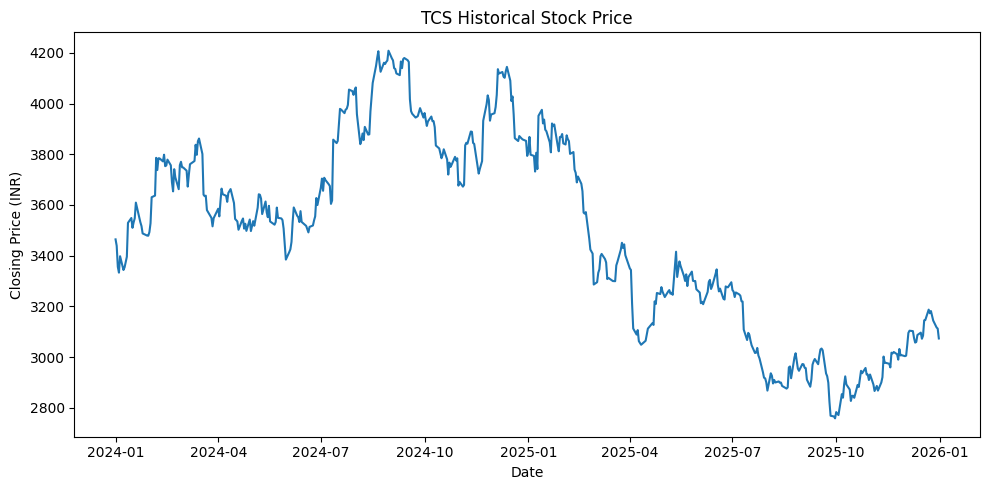

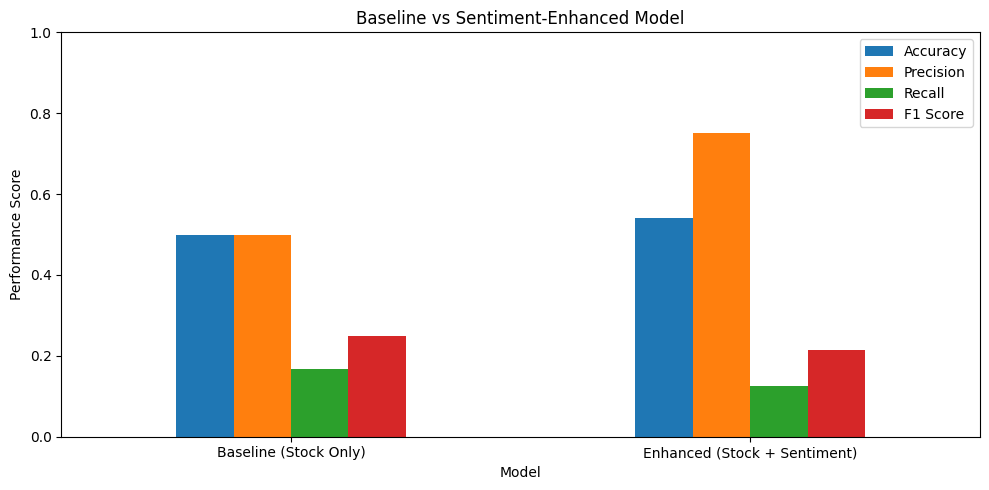

All four visualizations saved successfully!


In [18]:

# STEP 17: Create project folders and save visualizations

import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("project_submission/dataset", exist_ok=True)
os.makedirs("project_submission/visualizations", exist_ok=True)

# 1. Sentiment distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=social_df, x="Sentiment")
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Posts")
plt.tight_layout()
plt.savefig("project_submission/visualizations/sentiment_distribution.png")
plt.show()

# 2. Trending topics
plt.figure(figsize=(9, 5))
sns.barplot(data=trending_df.head(10), x="Frequency", y="Topic")
plt.title("Top 10 Trending Topics")
plt.tight_layout()
plt.savefig("project_submission/visualizations/trending_topics.png")
plt.show()

# 3. Stock price trend
plt.figure(figsize=(10, 5))
plt.plot(stock_df["Date"], stock_df["Close"])
plt.title("TCS Historical Stock Price")
plt.xlabel("Date")
plt.ylabel("Closing Price (INR)")
plt.tight_layout()
plt.savefig("project_submission/visualizations/stock_price_trend.png")
plt.show()

# 4. Model comparison
comparison.plot(kind="bar", figsize=(10, 5))
plt.title("Baseline vs Sentiment-Enhanced Model")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("project_submission/visualizations/model_comparison.png")
plt.show()

print("All four visualizations saved successfully!")


In [19]:

# STEP 18: Organize project datasets

social_df.to_csv(
    "project_submission/dataset/social_media_posts.csv",
    index=False
)

stock_df.to_csv(
    "project_submission/dataset/stock_data.csv",
    index=False
)

social_df.to_csv(
    "project_submission/dataset/sentiment_analysis_results.csv",
    index=False
)

combined_df.to_csv(
    "project_submission/dataset/combined_financial_sentiment_data.csv",
    index=False
)

results_df.to_csv(
    "project_submission/dataset/model_comparison_results.csv",
    index=False
)

print("All datasets organized successfully!")


All datasets organized successfully!


In [20]:

requirements = """pandas
numpy
yfinance
nltk
scikit-learn
matplotlib
seaborn
"""

with open("project_submission/requirements.txt", "w") as f:
    f.write(requirements)

print("requirements.txt created!")


requirements.txt created!


In [21]:

# STEP 19: Create README.md

accuracy_baseline = results_df.iloc[0]["Accuracy"]
accuracy_enhanced = results_df.iloc[1]["Accuracy"]

readme = f"""
# Social Media Sentiment and Financial Trend Prediction

## 1. Project Overview

This project analyzes social media sentiment and historical
stock market data to investigate whether public opinion is
associated with subsequent stock price movements.

It classifies social media posts into Positive, Negative,
and Neutral categories, identifies trending topics, and
predicts the next trading day's stock price direction.

## 2. Objectives

- Perform sentiment analysis on sample social media posts.
- Identify trending financial topics.
- Collect historical stock market information.
- Combine sentiment features with financial indicators.
- Predict upward or downward stock movements.
- Compare a baseline model with a sentiment-enhanced model.

## 3. Technologies Used

- Python
- Google Colab
- Pandas and NumPy
- NLTK VADER
- Scikit-learn
- Random Forest Classifier
- Matplotlib and Seaborn
- Yahoo Finance (yfinance)

## 4. Dataset Description

### Social Media Dataset

File: social_media_posts.csv

Contains 100 synthetic sample posts about TCS, Infosys,
and Wipro, with dates and company names.

The posts are created for academic demonstration.
They are not actual social media posts.

### Stock Market Dataset

File: stock_data.csv

Historical TCS stock market data downloaded using
Yahoo Finance through the yfinance Python library.

Ticker: TCS.NS

Period requested: 2024-01-01 to 2026-01-01.

## 5. Data Processing

- Prepared and cleaned text data.
- Classified posts using VADER sentiment scores.
- Aggregated sentiment scores by date.
- Calculated daily stock returns.
- Calculated 5-day and 10-day moving averages.
- Calculated stock price volatility.
- Created next-day UP/DOWN prediction labels.
- Handled missing and infinite values.

## 6. Algorithms

### Sentiment Analysis

VADER (Valence Aware Dictionary and sEntiment Reasoner)
is used to calculate sentiment polarity.

### Trending Topic Identification

CountVectorizer is used to identify frequently
occurring words and topics.

### Financial Prediction

Random Forest Classifier is used to predict the
next trading day's stock direction.

## 7. Model Comparison

Two models are evaluated:

1. Baseline: Historical stock price and technical features.
2. Enhanced: Historical features combined with sentiment.

A chronological 80:20 train-test split is used.

### Actual Model Results

| Metric | Baseline | Enhanced |
|---|---:|---:|
| Accuracy | {accuracy_baseline:.4f} | {accuracy_enhanced:.4f} |

See model_comparison_results.csv for all evaluation metrics.

## 8. Evaluation Metrics

- Accuracy
- Precision
- Recall
- F1-score

## 9. Visualizations

The visualizations folder contains:

1. Sentiment distribution.
2. Trending topics.
3. Historical stock prices.
4. Baseline vs enhanced model performance.

## 10. Installation

Install the dependencies:

pip install -r requirements.txt

## 11. Execution Instructions

1. Open Google Colab.
2. Upload Social_Media_Sentiment_Financial_Prediction.ipynb.
3. Run the notebook cells sequentially.
4. Connect to the internet to download stock data.
5. Review sentiment reports, graphs and predictions.

## 12. Limitations

- Social media posts are synthetic sample data.
- Sentiment results do not represent actual investor opinion.
- The sample dataset is limited in size and time coverage.
- Stock market movements are affected by many factors.
- Predictions are experimental and not investment advice.

## 13. Conclusion

The project demonstrates how Natural Language Processing
and Machine Learning can be combined to study the
relationship between public sentiment and financial trends.

It compares historical-price-only prediction against
sentiment-enhanced prediction using a time-based split.
"""

with open("project_submission/README.md", "w", encoding="utf-8") as f:
    f.write(readme)

print("README.md created successfully!")


README.md created successfully!


In [22]:

# DATA VALIDATION: Restrict analysis to the available
# social media sentiment period

max_sentiment_date = daily_sentiment['Date'].max()

combined_df = combined_df[
    combined_df['Date'] <= max_sentiment_date
].copy()

print("Latest available sentiment date:", max_sentiment_date)
print("Valid combined records:", len(combined_df))

# Recalculate financial features after filtering
combined_df = combined_df.sort_values('Date').copy()

combined_df['Daily_Return'] = combined_df['Close'].pct_change(fill_method=None)
combined_df['Previous_Return'] = combined_df['Daily_Return'].shift(1)
combined_df['MA_5'] = combined_df['Close'].rolling(5).mean()
combined_df['MA_10'] = combined_df['Close'].rolling(10).mean()
combined_df['Volatility'] = combined_df['Daily_Return'].rolling(5).std()
combined_df['Volume_Change'] = combined_df['Volume'].pct_change(fill_method=None)

combined_df['Next_Close'] = combined_df['Close'].shift(-1)

combined_df['Target'] = np.where(
    combined_df['Next_Close'].notna(),
    (combined_df['Next_Close'] > combined_df['Close']).astype(int),
    np.nan
)

combined_df.replace([np.inf, -np.inf], np.nan, inplace=True)
combined_df.dropna(inplace=True)

print("Data validation completed!")
display(combined_df.head())


Latest available sentiment date: 2025-04-10 00:00:00
Valid combined records: 59
Data validation completed!


,Date,Close,High,Low,Open,Volume,daily_sentiment,positive_ratio,negative_ratio,neutral_ratio,post_count,Daily_Return,Previous_Return,MA_5,MA_10,Volatility,Volume_Change,Next_Close,Target
264,2025-01-27,3835.260742,3921.303456,3812.523765,3870.026922,1551782,0.296,1.0,0.0,0.0,1.0,-0.021000,0.001665,3878.593164,3888.629858,0.019045,-0.187591,3811.816162,0.0
265,2025-01-28,3811.816162,3870.026906,3800.494777,3840.591350,2468272,0.000,0.0,0.0,1.0,1.0,-0.006113,-0.021000,3879.432959,3877.660742,0.018594,0.590605,3867.950684,1.0
266,2025-01-29,3867.950684,3875.545722,3824.740919,3824.740919,1217089,0.000,0.0,0.0,1.0,1.0,0.014726,-0.006113,3868.715332,3870.771899,0.012935,-0.506906,3868.186523,1.0
267,2025-01-30,3868.186523,3896.348558,3828.986416,3868.045098,1531251,0.000,0.0,0.0,1.0,1.0,0.000061,0.014726,3860.148779,3867.917944,0.012993,0.258126,3879.838379,1.0
268,2025-01-31,3879.838379,3894.981007,3854.223839,3877.574194,1492943,0.765,1.0,0.0,0.0,1.0,0.003012,0.000061,3852.610498,3866.795264,0.013105,-0.025017,3842.808105,0.0


In [23]:

# STEP 20: Final project packaging

import shutil
import os

# Save final prediction results
prediction_report = pd.DataFrame({
    "Date": [combined_df['Date'].iloc[-1]],
    "Predicted_Trend": [
        "UP" if enhanced_model.predict(
            combined_df[enhanced_features].tail(1)
        )[0] == 1 else "DOWN"
    ]
})

prediction_report.to_csv(
    "project_submission/dataset/financial_trend_prediction.csv",
    index=False
)

# Create ZIP archive
shutil.make_archive(
    "Social_Media_Sentiment_Project",
    "zip",
    "project_submission"
)

print("====================================")
print("PROJECT PACKAGING COMPLETED!")
print("====================================")

print("Files inside project folder:")

for root, dirs, files in os.walk("project_submission"):
    for file in files:
        print(os.path.join(root, file))

# Download ZIP file to your computer
from google.colab import files

files.download("Social_Media_Sentiment_Project.zip")


PROJECT PACKAGING COMPLETED!
Files inside project folder:
project_submission/requirements.txt
project_submission/README.md
project_submission/dataset/model_comparison_results.csv
project_submission/dataset/sentiment_analysis_results.csv
project_submission/dataset/social_media_posts.csv
project_submission/dataset/financial_trend_prediction.csv
project_submission/dataset/stock_data.csv
project_submission/dataset/combined_financial_sentiment_data.csv
project_submission/visualizations/trending_topics.png
project_submission/visualizations/stock_price_trend.png
project_submission/visualizations/sentiment_distribution.png
project_submission/visualizations/model_comparison.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>